# Detecting Forged Handwritten Signatures with a CNN

**UCS321 AI for Engineers, Assignment 2**
**Name:** Akshara Thapan  |  **Roll No.:** 7025000032
**Topic:** T-178, Detecting forged handwritten signatures (binary image classification)

The whole notebook runs top to bottom in Google Colab with no login or Kaggle token. A GPU runtime takes a few minutes; CPU takes about 40 minutes.

In [1]:
import hashlib, io, json, re, time, urllib.request, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42
IMG_H, IMG_W = 96, 192     # every signature becomes a 96 x 192 image
BATCH_SIZE = 32
EPOCHS = 15                # the best epoch is chosen on the validation set
CONTROL_EPOCHS = 6         # the raw-image control converges almost at once
N_REFS = 5                 # genuine signatures enrolled for each person
GENUINE, FORGED = 0, 1     # forged is the positive class
COLORS = {"Genuine": "#2a78d6", "Forged": "#eb6834"}
device = "cuda" if torch.cuda.is_available() else "cpu"

def seed_all(seed):
    torch.manual_seed(seed)
    return np.random.default_rng(seed)

rng = seed_all(SEED)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RESULTS = {}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True})
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cpu | device: cpu


## 1. Problem statement

Banks, courts and offices still accept handwritten signatures, and checking them by eye is slow and depends on the examiner. This project asks whether a convolutional neural network can tell a genuine signature from a skilled forgery. The output is binary: genuine or forged. A useful system must work for people it has never seen, so the model is always tested on signers kept completely out of training.

## 2. Dataset

**CEDAR Signature Database** (Kalera, Srihari and Xu, 2004): 55 signers, each with 24 genuine signatures and 24 skilled forgeries, scanned at 300 dpi. The official copy is a RAR file on the University at Buffalo site, so this notebook loads a public GitHub copy of the same images, pinned to one commit so the data cannot change between runs.

- Source: <https://cedar.buffalo.edu/NIJ/data/signatures.rar>
- Direct URL used here: <https://github.com/Snehal-Aparadh/SignatureForgeryDetection>

In [2]:
COMMIT = "9e4157bb9b62f17b1837845cc38ee54604bae204"
DATA_URL = f"https://github.com/Snehal-Aparadh/SignatureForgeryDetection/archive/{COMMIT}.zip"
ZIP_PATH = Path("cedar_signatures.zip")

if not ZIP_PATH.exists():
    print("Downloading about 300 MB ...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

rows, blobs = [], {}
with zipfile.ZipFile(ZIP_PATH) as zf:
    for name in zf.namelist():
        match = re.search(r"/Dataset/(genuine_sign|forged_sign)/([^/]+\.png)$", name)
        if not match:
            continue
        data = zf.read(name)
        key = f"{match[1]}/{match[2]}"
        blobs[key] = data
        with Image.open(io.BytesIO(data)) as im:
            rows.append({"key": key, "folder": match[1], "file": match[2],
                         "width": im.width, "height": im.height, "mode": im.mode,
                         "md5": hashlib.md5(data).hexdigest()})

df = pd.DataFrame(rows)
print(len(df), "files loaded")
df.groupby("folder").agg(files=("file", "count"), median_width=("width", "median"),
                         median_height=("height", "median"))

2646 files loaded


,files,median_width,median_height
folder,,,
forged_sign,1323,576.0,336.0
genuine_sign,1323,577.0,349.0


## 3. Pre-processing

**Missing values and duplicates.** An image dataset has no blank cells, so "missing" here means a signer or sample that should exist but does not. Each folder also turns out to hold three extra test files, which are byte-for-byte copies.

In [3]:
pattern = r"^(original|forgeries)_(\d+)_(\d+)\.png$"
parts = df["file"].str.extract(pattern)
extra = df[parts[0].isna()]
print("Files outside the naming scheme:", len(extra))
print("Of those, exact copies of another file:",
      int(extra["md5"].isin(df.loc[parts[0].notna(), "md5"]).sum()))

df = df[parts[0].notna()].copy()
df[["kind", "writer", "sample"]] = parts.loc[df.index].values
df["writer"] = df["writer"].astype(int)
df["sample"] = df["sample"].astype(int)
df["label"] = (df["kind"] == "forgeries").astype(int)     # encoding: genuine 0, forged 1
df = df.sort_values(["writer", "label", "sample"]).reset_index(drop=True)

per_person = df.groupby(["writer", "label"]).size()
RESULTS["n_images"] = len(df)
RESULTS["n_writers"] = int(df["writer"].nunique())
RESULTS["n_extra_removed"] = len(extra)
print("Images kept:", len(df), "| signers:", df["writer"].nunique())
print("Signer and class combinations with exactly 24 images:", int((per_person == 24).sum()), "of", len(per_person))
print("Duplicate images remaining:", int(df["md5"].duplicated().sum()))

Files outside the naming scheme: 6
Of those, exact copies of another file: 6
Images kept: 2640 | signers: 55
Signer and class combinations with exactly 24 images: 110 of 110
Duplicate images remaining: 0


**Checking the scans.** Before cleaning anything, I measured each image's background brightness (its median grey level) and how much of it is ink. Otsu's method picks the threshold that best separates ink from paper in each image.

In [4]:
def otsu_threshold(gray):
    counts = np.bincount(gray.ravel(), minlength=256).astype(float)
    prob = counts / counts.sum()
    omega = np.cumsum(prob)
    mu = np.cumsum(prob * np.arange(256))
    between = (mu[-1] * omega - mu) ** 2 / (omega * (1 - omega) + 1e-12)
    return int(between.argmax())

def letterbox(image):
    # Resize to fit IMG_H x IMG_W, keep the shape, pad the rest with zeros.
    ratio = min(IMG_W / image.width, IMG_H / image.height)
    size = (max(1, round(image.width * ratio)), max(1, round(image.height * ratio)))
    canvas = Image.new("L", (IMG_W, IMG_H), 0)
    canvas.paste(image.resize(size, Image.BILINEAR),
                 ((IMG_W - size[0]) // 2, (IMG_H - size[1]) // 2))
    return np.asarray(canvas, dtype=np.float32) / 255      # scaling: 0 to 1

raw_images, clean_images, background, ink = [], [], [], []
for key in df["key"]:
    gray = np.asarray(Image.open(io.BytesIO(blobs[key])).convert("L"))
    mask = gray <= otsu_threshold(gray)
    rows_ink, cols_ink = np.where(mask)
    box = (cols_ink.min(), rows_ink.min(), cols_ink.max() + 1, rows_ink.max() + 1)
    background.append(np.median(gray))
    ink.append(mask.mean())
    raw_images.append(letterbox(Image.fromarray(255 - gray)))
    clean_images.append(letterbox(Image.fromarray((mask * 255).astype(np.uint8)).crop(box)))

X_raw = np.stack(raw_images)
X_clean = np.stack(clean_images)
df["background"] = background
df["ink_fraction"] = ink
df["aspect"] = df["width"] / df["height"]
del blobs, raw_images, clean_images

df.groupby("kind")[["background", "ink_fraction", "aspect"]].agg(["mean", "std", "min", "max"]).round(3)

background                      ink_fraction                       \
                mean    std    min    max         mean    std    min    max   
kind                                                                          
forgeries    253.496  1.595  249.0  255.0        0.036  0.015  0.012  0.093   
original     239.768  2.356  234.0  245.0        0.035  0.013  0.010  0.105   

          aspect                       
            mean    std    min    max  
kind                                   
forgeries  1.679  0.483  0.778  4.038  
original   1.571  0.426  0.714  4.055

**Outliers.** The 1.5×IQR rule flags unusual shapes and ink amounts. These are real signatures, some just long or sparse, so I keep them. Letterboxing handles their shape.

**The important finding.** The table above shows the two classes do not overlap at all on background brightness (genuine at most 245, forged at least 249), which has nothing to do with handwriting. It comes from how the two groups were scanned. Section 4 plots it. A model given the raw images could score perfectly by reading the paper, so I prepare two versions of the data:

- **Raw:** grey image, inverted and resized. Used only as a control.
- **Clean:** ink kept as a black-and-white mask (Otsu), cropped to the signature, then resized. Every background is identical, so only the pen strokes remain. All real models use this version.

**Split.** Splitting by signer, not by image, means no person appears in two sets. That is the only way to measure performance on new people. About 70/15/15 by signer. Nothing is fitted on validation or test data.

In [5]:
def iqr_outliers(values):
    q1, q3 = values.quantile([.25, .75])
    gap = 1.5 * (q3 - q1)
    return (values < q1 - gap) | (values > q3 + gap)

RESULTS["outliers_aspect"] = int(iqr_outliers(df["aspect"]).sum())
RESULTS["outliers_ink"] = int(iqr_outliers(df["ink_fraction"]).sum())
print("Outliers kept -> aspect ratio:", RESULTS["outliers_aspect"], "| ink fraction:", RESULTS["outliers_ink"])

def writer_split(seed):
    order = np.random.default_rng(seed).permutation(sorted(df["writer"].unique()))
    return order[16:], order[8:16], order[:8]     # train, validation, test

labels = df["label"].to_numpy(np.int64)
writers = df["writer"].to_numpy()
samples = df["sample"].to_numpy()

train_w, val_w, test_w = writer_split(SEED)
assert not (set(train_w) & set(val_w) or set(train_w) & set(test_w) or set(val_w) & set(test_w))
train_idx = np.where(np.isin(writers, train_w))[0]
val_idx = np.where(np.isin(writers, val_w))[0]
test_idx = np.where(np.isin(writers, test_w))[0]

def genuine_of(writer):
    idx = np.where((writers == writer) & (labels == GENUINE))[0]
    return idx[np.argsort(samples[idx])]

def enrolled(writer):
    return genuine_of(writer)[:N_REFS]

def queries(writer_set):
    # Everything except the enrolled references: 19 genuine and 24 forged per person.
    used = np.concatenate([enrolled(w) for w in writer_set])
    pool = np.where(np.isin(writers, writer_set))[0]
    return pool[~np.isin(pool, used)]

val_q, test_q = queries(val_w), queries(test_w)
split_table = pd.DataFrame({
    "signers": [len(train_w), len(val_w), len(test_w)],
    "images": [len(train_idx), len(val_idx), len(test_idx)],
    "evaluated images": ["-", len(val_q), len(test_q)],
}, index=["train", "validation", "test"])
RESULTS["split"] = split_table.astype(str).to_dict()
RESULTS["test_queries"] = len(test_q)
split_table

Outliers kept -> aspect ratio: 102 | ink fraction: 61


,signers,images,evaluated images
train,39,1872,-
validation,8,384,344
test,8,384,344


## 4. Exploratory data analysis

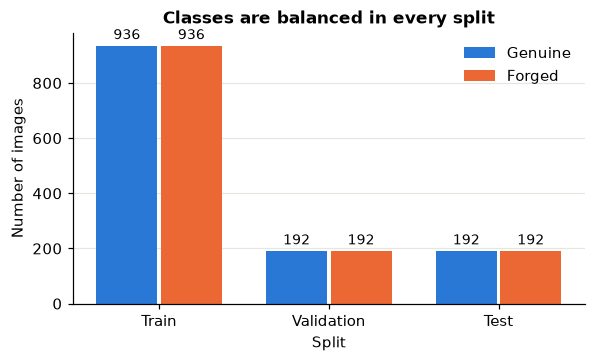

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.2))
names = ["Train", "Validation", "Test"]
sets = [train_idx, val_idx, test_idx]
for offset, (label_name, value) in zip((-.19, .19), (("Genuine", GENUINE), ("Forged", FORGED))):
    counts = [int((labels[s] == value).sum()) for s in sets]
    bars = ax.bar(np.arange(3) + offset, counts, .36, color=COLORS[label_name], label=label_name)
    ax.bar_label(bars, padding=2, fontsize=9)
ax.set_xticks(range(3), names); ax.set_xlabel("Split"); ax.set_ylabel("Number of images")
ax.set_title("Classes are balanced in every split"); ax.grid(axis="x", visible=False); ax.legend(frameon=False)
fig.savefig(FIG_DIR / "class_balance.png"); plt.show()

Each person gave the same number of genuine and forged samples, so a majority-class guess gets 50% and accuracy is a fair metric.

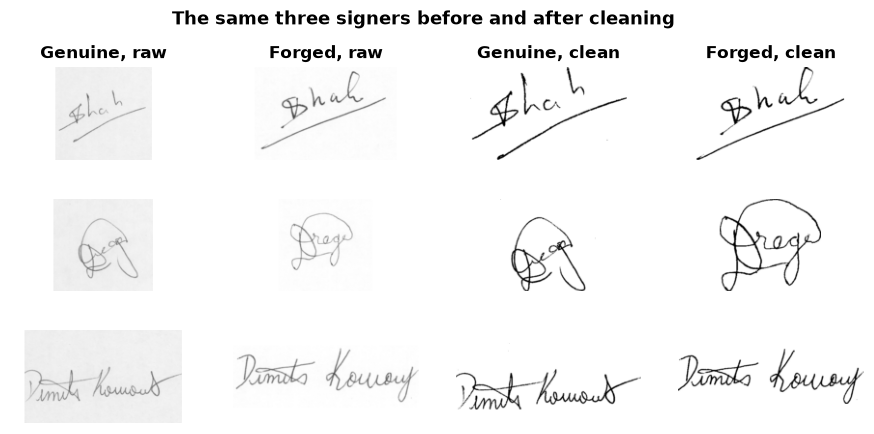

In [7]:
show = list(rng.choice(train_w, 3, replace=False))
fig, axes = plt.subplots(3, 4, figsize=(10, 4.4))
for row, writer in enumerate(show):
    genuine = np.where((writers == writer) & (labels == GENUINE))[0][0]
    forged = np.where((writers == writer) & (labels == FORGED))[0][0]
    panels = [(X_raw[genuine], "Genuine, raw"), (X_raw[forged], "Forged, raw"),
              (X_clean[genuine], "Genuine, clean"), (X_clean[forged], "Forged, clean")]
    for col, (image, title) in enumerate(panels):
        axes[row, col].imshow(1 - image, cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(title)
fig.suptitle("The same three signers before and after cleaning", fontweight="bold")
fig.savefig(FIG_DIR / "samples.png"); plt.show()

The forgeries are skilled copies of the same name, so telling the classes apart by eye from one image is hard. The raw genuine images also look slightly greyer than the forged ones.

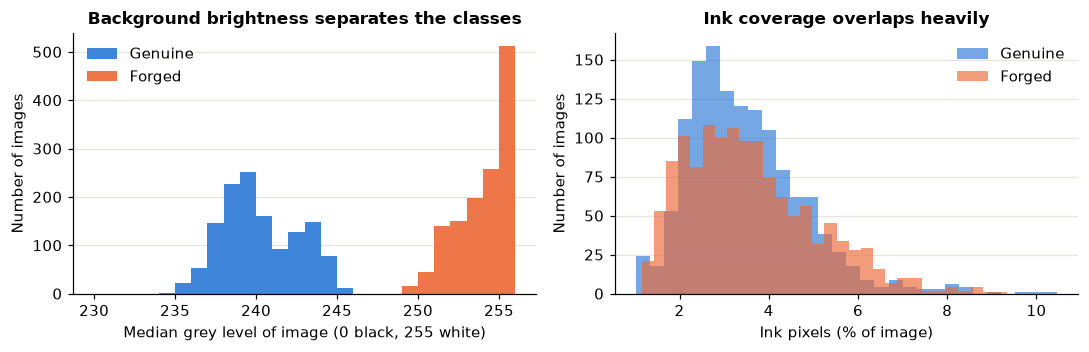

One-line rule 'background > 247.0 means forged' -> test accuracy 1.000


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
bins = np.arange(230, 257)
for label_name, value in (("Genuine", GENUINE), ("Forged", FORGED)):
    part = df[df["label"] == value]
    axes[0].hist(part["background"], bins=bins, color=COLORS[label_name], label=label_name, alpha=.9)
    axes[1].hist(part["ink_fraction"] * 100, bins=30, color=COLORS[label_name], label=label_name, alpha=.65)
axes[0].set_title("Background brightness separates the classes")
axes[0].set_xlabel("Median grey level of image (0 black, 255 white)"); axes[0].set_ylabel("Number of images")
axes[1].set_title("Ink coverage overlaps heavily")
axes[1].set_xlabel("Ink pixels (% of image)"); axes[1].set_ylabel("Number of images")
for ax in axes:
    ax.legend(frameon=False); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "background_artefact.png"); plt.show()

# How far does a single brightness threshold go? The cut-off comes from training signers only.
train_bg = df.loc[train_idx]
cut = (train_bg.loc[train_bg["label"] == GENUINE, "background"].max()
       + train_bg.loc[train_bg["label"] == FORGED, "background"].min()) / 2
rule_pred = (df.loc[test_q, "background"] > cut).astype(int)
RESULTS["background_cut"] = float(cut)
RESULTS["background_rule_acc"] = float(accuracy_score(labels[test_q], rule_pred))
RESULTS["background_medians"] = {
    "genuine": float(df.loc[df["label"] == GENUINE, "background"].median()),
    "forged": float(df.loc[df["label"] == FORGED, "background"].median())}
print(f"One-line rule 'background > {cut:.1f} means forged' -> test accuracy {RESULTS['background_rule_acc']:.3f}")

Those two plots drive the design of this project. A single brightness threshold almost solves the problem without looking at a signature, so a high score on raw images would prove nothing. Ink coverage overlaps heavily, which is closer to the real difficulty.

## 5. Model building

The topic names a CNN, so three CNNs are built with the same convolutional blocks (convolution, batch normalisation, ReLU, max pooling).

1. **Single-image CNN:** sees only the signature in question.
2. **Reference CNN:** the main model. It sees the signature and one enrolled genuine signature of the same person, which is how real verification works: a bank compares against a specimen on file. The two signatures are stacked as a two-channel image, so the first filters can compare strokes directly.
3. **Raw-image control:** the single-image CNN on raw images, kept only to measure the artefact.

Choices: Adam (learning rate 0.001, reduced smoothly by a cosine schedule) with light weight decay; cross-entropy loss; dropout 0.3; and small random rotation, scale and shift, because nobody signs identically twice. The weights from the epoch with the best validation accuracy are kept.

In [9]:
def blocks(in_channels):
    layers, channels = [], in_channels
    for out_channels in (16, 32, 64, 128):
        layers += [nn.Conv2d(channels, out_channels, 3, padding=1, bias=False),
                   nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
        channels = out_channels
    return nn.Sequential(*layers)

class SingleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = blocks(1)
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(.3), nn.Linear(128, 2))
    def forward(self, x):
        return self.classifier(self.features(x))

class ReferenceCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = blocks(2)      # channel 1: reference, channel 2: signature to check
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(.3), nn.Linear(128, 2))
    def forward(self, reference, query):
        return self.classifier(self.features(torch.cat([reference, query], 1)))

def augment(x):
    n = x.size(0)
    angle = (torch.rand(n, device=x.device) - .5) * .17    # about +/- 5 degrees
    scale = 1 + (torch.rand(n, device=x.device) - .5) * .2
    theta = torch.zeros(n, 2, 3, device=x.device)
    theta[:, 0, 0] = scale * torch.cos(angle); theta[:, 0, 1] = -scale * torch.sin(angle)
    theta[:, 1, 0] = scale * torch.sin(angle); theta[:, 1, 1] = scale * torch.cos(angle)
    theta[:, 0, 2] = (torch.rand(n, device=x.device) - .5) * .1
    theta[:, 1, 2] = (torch.rand(n, device=x.device) - .5) * .1
    return F.grid_sample(x, F.affine_grid(theta, x.size(), align_corners=False), align_corners=False)

def single_probs(model, X, idx):
    model.eval(); out = []
    with torch.no_grad():
        for start in range(0, len(idx), 128):
            batch = X[idx[start:start + 128]].to(device)
            out.append(F.softmax(model(batch), 1)[:, 1].cpu())
    return torch.cat(out).numpy()

def ref_probs(model, X, idx):
    # Average the forged probability over the person's enrolled references.
    model.eval(); out = np.zeros(len(idx))
    groups = pd.Series(np.arange(len(idx))).groupby(writers[idx])
    with torch.no_grad():
        for writer, positions in groups.groups.items():
            q = idx[np.asarray(positions)]
            total = 0
            for ref in enrolled(writer):
                for_batches = [F.softmax(model(X[np.full(len(q[s:s + 128]), ref)].to(device),
                                               X[q[s:s + 128]].to(device)), 1)[:, 1].cpu()
                               for s in range(0, len(q), 128)]
                total = total + torch.cat(for_batches).numpy()
            out[np.asarray(positions)] = total / N_REFS
    return out

def fit(model, idx, make_inputs, validate, epochs, seed):
    r = seed_all(seed)
    model.to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, epochs)
    order, best_acc, best_state, history, started = idx.copy(), -1, None, [], time.time()
    for epoch in range(1, epochs + 1):
        model.train(); r.shuffle(order); total = 0
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            target = torch.as_tensor(labels[batch]).to(device)
            optimiser.zero_grad()
            loss = F.cross_entropy(model(*make_inputs(batch, r)), target)
            loss.backward(); optimiser.step()
            total += loss.item() * len(batch)
        schedule.step()
        val_acc = validate(model)
        history.append({"epoch": epoch, "train_loss": total / len(order), "val_accuracy": val_acc})
        if val_acc >= best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    best_epoch = max(history, key=lambda h: (h["val_accuracy"], h["epoch"]))["epoch"]
    print(f"{type(model).__name__}: best epoch {best_epoch}, validation accuracy {best_acc:.3f}, {time.time() - started:.0f} s")
    return pd.DataFrame(history)

T_raw = torch.from_numpy(X_raw)[:, None]
T_clean = torch.from_numpy(X_clean)[:, None]

def single_inputs(X):
    return lambda batch, r: (augment(X[batch].to(device)),)

def reference_inputs(X, batch, r):
    refs = []
    for i in batch:
        pool = genuine_of(writers[i])
        refs.append(r.choice(pool[pool != i]))
    return augment(X[np.array(refs)].to(device)), augment(X[batch].to(device))

def val_single(X, idx):
    return lambda m: accuracy_score(labels[idx], single_probs(m, X, idx) > .5)

def val_reference(X, idx):
    return lambda m: accuracy_score(labels[idx], ref_probs(m, X, idx) > .5)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

print("Parameters -> single:", n_params(SingleCNN()), "| reference:", n_params(ReferenceCNN()))

Parameters -> single: 97650 | reference: 97794


In [10]:
single_model = SingleCNN()
single_hist = fit(single_model, train_idx, single_inputs(T_clean), val_single(T_clean, val_q), EPOCHS, SEED)

ref_model = ReferenceCNN()
ref_hist = fit(ref_model, train_idx, lambda b, r: reference_inputs(T_clean, b, r),
               val_reference(T_clean, val_q), EPOCHS, SEED)

control_model = SingleCNN()
control_hist = fit(control_model, train_idx, single_inputs(T_raw), val_single(T_raw, val_q), CONTROL_EPOCHS, SEED)

SingleCNN: best epoch 10, validation accuracy 0.794, 368 s


ReferenceCNN: best epoch 12, validation accuracy 0.814, 442 s


SingleCNN: best epoch 6, validation accuracy 1.000, 133 s


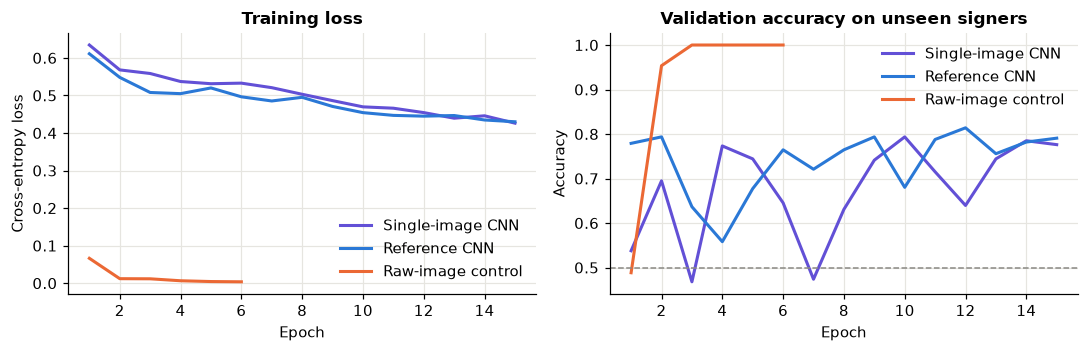

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
curves = [("Single-image CNN", single_hist, "#6250d6"), ("Reference CNN", ref_hist, "#2a78d6"),
          ("Raw-image control", control_hist, "#eb6834")]
for name, hist, color in curves:
    axes[0].plot(hist["epoch"], hist["train_loss"], color=color, lw=2, label=name)
    axes[1].plot(hist["epoch"], hist["val_accuracy"], color=color, lw=2, label=name)
axes[0].set_title("Training loss"); axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_title("Validation accuracy on unseen signers"); axes[1].set_ylabel("Accuracy")
axes[1].axhline(.5, color="#8a8984", ls="--", lw=1)
for ax in axes:
    ax.set_xlabel("Epoch"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "learning_curves.png"); plt.show()

## 6. Comparison with other models

All models are scored on the same test signatures. Logistic Regression, an RBF SVM and a Random Forest use the cleaned image shrunk to 24 × 48 pixels. A fourth model, the Reference SVM, gets the same information as the Reference CNN (the absolute difference between the signature and a reference), which shows what the convolutional layers add.

In [12]:
def shrink(idx):
    return F.avg_pool2d(T_clean[idx], 4).flatten(1).numpy()

X_tr, y_tr = shrink(train_idx), labels[train_idx]
X_te = shrink(test_q)
classic = {
    "Logistic Regression": make_pipeline(StandardScaler(), PCA(100, random_state=SEED),
                                         LogisticRegression(max_iter=2000, random_state=SEED)),
    "SVM (RBF)": make_pipeline(StandardScaler(), PCA(100, random_state=SEED), SVC(probability=True, random_state=SEED)),
    "Random Forest": RandomForestClassifier(300, random_state=SEED, n_jobs=-1),
}
scores = {}
for name, model in classic.items():
    model.fit(X_tr, y_tr)
    scores[name] = model.predict_proba(X_te)[:, 1]

def diff_features(ref_idx, query_idx):
    return np.abs(shrink(ref_idx) - shrink(query_idx))

r = seed_all(SEED)
pairs = [(r.choice(genuine_of(writers[i])[genuine_of(writers[i]) != i]), i) for i in np.repeat(train_idx, 3)]
pair_ref, pair_query = map(np.array, zip(*pairs))
ref_svm = make_pipeline(StandardScaler(), PCA(100, random_state=SEED), SVC(probability=True, random_state=SEED))
ref_svm.fit(diff_features(pair_ref, pair_query), labels[pair_query])

svm_scores = np.zeros(len(test_q))
for writer in test_w:
    where = np.where(writers[test_q] == writer)[0]
    for ref in enrolled(writer):
        svm_scores[where] += ref_svm.predict_proba(diff_features(np.full(len(where), ref), test_q[where]))[:, 1] / N_REFS
scores["Reference SVM"] = svm_scores
scores["Single-image CNN"] = single_probs(single_model, T_clean, test_q)
scores["Reference CNN"] = ref_probs(ref_model, T_clean, test_q)
scores["Raw-image control (invalid)"] = single_probs(control_model, T_raw, test_q)

## 7. Evaluation

**Metrics.** Accuracy alone hides the two ways this system can fail, so I also report precision, recall, F1 and ROC AUC with *forged* as the positive class, plus:

- **FAR (false acceptance rate):** share of forgeries accepted as genuine. This is the costly mistake.
- **FRR (false rejection rate):** share of genuine signatures rejected. This annoys real customers.

The test set was used only here, after all design choices were made.

In [13]:
y_test = labels[test_q]

def evaluate(y, p, threshold=.5):
    pred = (p > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred), "ROC AUC": roc_auc_score(y, p),
            "FAR": fn / (fn + tp), "FRR": fp / (fp + tn)}

table = pd.DataFrame({name: evaluate(y_test, p) for name, p in scores.items()}).T
table = table.sort_values("Accuracy", ascending=False)
RESULTS["table"] = table.round(4).to_dict("index")
table.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC,FAR,FRR
Raw-image control (invalid),1.000,1.000,1.000,1.000,1.000,0.000,0.000
Reference CNN,0.788,0.805,0.818,0.811,0.861,0.182,0.250
Single-image CNN,0.701,0.694,0.828,0.755,0.792,0.172,0.461
Random Forest,0.581,0.638,0.578,0.607,0.564,0.422,0.414
Reference SVM,0.555,0.577,0.760,0.656,0.606,0.240,0.704
SVM (RBF),0.547,0.596,0.583,0.589,0.574,0.417,0.500
Logistic Regression,0.474,0.531,0.484,0.507,0.479,0.516,0.539


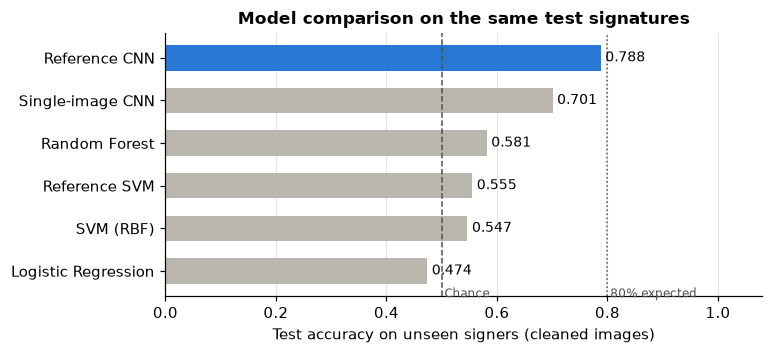

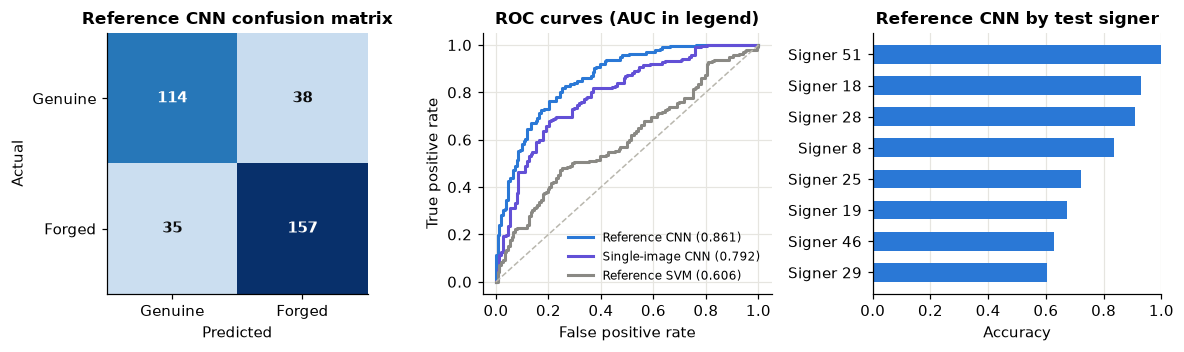

In [14]:
valid = table.drop("Raw-image control (invalid)")
fig, ax = plt.subplots(figsize=(7, 3.1))
bars = ax.barh(valid.index[::-1], valid["Accuracy"][::-1],
               color=["#2a78d6" if n == "Reference CNN" else "#b9b7ae" for n in valid.index[::-1]], height=.6)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axvline(.5, color="#52514e", ls="--", lw=1); ax.text(.505, -0.62, "Chance", fontsize=8, color="#52514e")
ax.axvline(.8, color="#52514e", ls=":", lw=1); ax.text(.805, -0.62, "80% expected", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.08); ax.set_xlabel("Test accuracy on unseen signers (cleaned images)")
ax.set_title("Model comparison on the same test signatures"); ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "model_comparison.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
best = scores["Reference CNN"]
cm = confusion_matrix(y_test, (best > .5).astype(int))
axes[0].imshow(cm, cmap="Blues", vmin=0); axes[0].grid(False)
for (row, col), value in np.ndenumerate(cm):
    axes[0].text(col, row, int(value), ha="center", va="center",
                 color="white" if value > cm.max() * .55 else "#0b0b0b", fontweight="bold")
axes[0].set_xticks([0, 1], ["Genuine", "Forged"]); axes[0].set_yticks([0, 1], ["Genuine", "Forged"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Reference CNN confusion matrix")

for name, color in (("Reference CNN", "#2a78d6"), ("Single-image CNN", "#6250d6"), ("Reference SVM", "#8a8984")):
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    axes[1].plot(fpr, tpr, lw=2, color=color, label=f"{name} ({roc_auc_score(y_test, scores[name]):.3f})")
axes[1].plot([0, 1], [0, 1], color="#b9b7ae", ls="--", lw=1)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curves (AUC in legend)"); axes[1].legend(frameon=False, fontsize=8)

per_writer = pd.Series((best > .5) == y_test).groupby(writers[test_q]).mean().sort_values()
axes[2].barh([f"Signer {w}" for w in per_writer.index], per_writer.values, color="#2a78d6", height=.6)
axes[2].set_xlim(0, 1); axes[2].set_xlabel("Accuracy"); axes[2].set_title("Reference CNN by test signer")
axes[2].grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "evaluation.png"); plt.show()
RESULTS["confusion_matrix"] = cm.tolist()
RESULTS["per_writer"] = {int(k): float(v) for k, v in per_writer.items()}

**Did it really learn the signature, and how much does the split matter?** Two more checks, on the same model designs:

1. **Stability:** the test set is only eight people, so one split could be lucky. I repeat the Reference CNN on two other signer splits.
2. **Leakage:** the single-image CNN is retrained with images shuffled at random, so one person appears in both train and test. The gain over the signer split is the score a careless split would have falsely reported.

In [15]:
stability = [{"seed": SEED, **{k: evaluate(y_test, best)[k] for k in ("Accuracy", "F1", "ROC AUC")}}]
for seed in (1, 2):
    tr_w, va_w, te_w = writer_split(seed)
    model = ReferenceCNN()
    fit(model, np.where(np.isin(writers, tr_w))[0], lambda b, r: reference_inputs(T_clean, b, r),
        val_reference(T_clean, queries(va_w)), EPOCHS, seed)
    q = queries(te_w)
    result = evaluate(labels[q], ref_probs(model, T_clean, q))
    stability.append({"seed": seed, **{k: result[k] for k in ("Accuracy", "F1", "ROC AUC")}})
stability = pd.DataFrame(stability).set_index("seed")
RESULTS["stability"] = stability.round(4).to_dict("index")
RESULTS["stability_mean"] = float(stability["Accuracy"].mean())
RESULTS["stability_std"] = float(stability["Accuracy"].std())
print(f"Reference CNN accuracy over 3 signer splits: {stability['Accuracy'].mean():.3f} +/- {stability['Accuracy'].std():.3f}")

r = np.random.default_rng(SEED).permutation(len(labels))
leak_test, leak_val, leak_train = r[:len(test_q)], r[len(test_q):2 * len(test_q)], r[2 * len(test_q):]
leak_model = SingleCNN()
fit(leak_model, leak_train, single_inputs(T_clean), val_single(T_clean, leak_val), EPOCHS, SEED)
RESULTS["leak_acc"] = float(accuracy_score(labels[leak_test], single_probs(leak_model, T_clean, leak_test) > .5))
RESULTS["single_acc"] = float(table.loc["Single-image CNN", "Accuracy"])
print(f"Single-image CNN -> random-image split {RESULTS['leak_acc']:.3f} | signer split {RESULTS['single_acc']:.3f}")
stability.round(3)

ReferenceCNN: best epoch 7, validation accuracy 0.834, 514 s


ReferenceCNN: best epoch 4, validation accuracy 0.747, 510 s


Reference CNN accuracy over 3 signer splits: 0.757 +/- 0.028


SingleCNN: best epoch 10, validation accuracy 0.794, 383 s


Single-image CNN -> random-image split 0.767 | signer split 0.701


,Accuracy,F1,ROC AUC
seed,,,
42,0.788,0.811,0.861
1,0.750,0.778,0.832
2,0.733,0.750,0.807


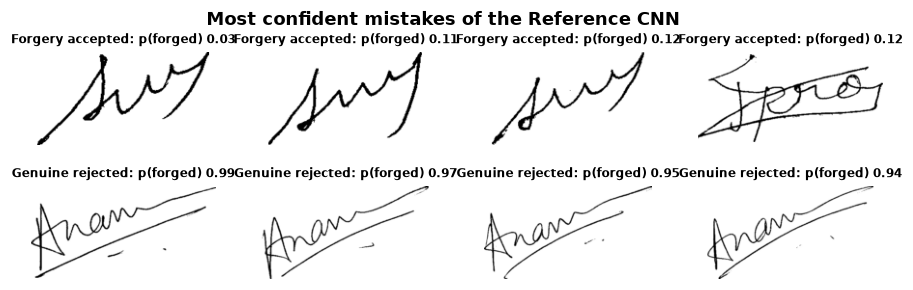

{
  "background_rule_acc": 1.0,
  "leak_acc": 0.7674418604651163,
  "single_acc": 0.7005813953488372,
  "stability_mean": 0.756782945736434,
  "stability_std": 0.02823411295413461
}


In [16]:
wrong = np.where((best > .5).astype(int) != y_test)[0]
false_accept = wrong[y_test[wrong] == FORGED]
false_accept = false_accept[np.argsort(best[false_accept])][:4]
false_reject = wrong[y_test[wrong] == GENUINE]
false_reject = false_reject[np.argsort(-best[false_reject])][:4]
fig, axes = plt.subplots(2, 4, figsize=(10, 2.9))
for row, (chosen, name) in enumerate(((false_accept, "Forgery accepted"), (false_reject, "Genuine rejected"))):
    for col in range(4):
        axes[row, col].axis("off")
        if col < len(chosen):
            axes[row, col].imshow(1 - X_clean[test_q[chosen[col]]], cmap="gray", vmin=0, vmax=1)
            axes[row, col].set_title(f"{name}: p(forged) {best[chosen[col]]:.2f}", fontsize=8)
fig.suptitle("Most confident mistakes of the Reference CNN", fontweight="bold")
fig.savefig(FIG_DIR / "errors.png"); plt.show()

Path("results.json").write_text(json.dumps(RESULTS, indent=2))
df[["writer", "label", "background", "ink_fraction", "aspect"]].to_csv("image_stats.csv", index=False)
single_hist.to_csv("history_single.csv", index=False); ref_hist.to_csv("history_reference.csv", index=False)
np.savez_compressed("test_scores.npz", test_q=test_q, y_test=y_test, test_w=test_w, **{k.replace(" ", "_"): v for k, v in scores.items()})
np.savez_compressed("test_images.npz", clean=(X_clean[np.isin(writers, test_w)] * 255).astype(np.uint8),
                    index=np.where(np.isin(writers, test_w))[0], enrolled={int(w): enrolled(w) for w in test_w})
torch.save(ref_model.state_dict(), "reference_cnn.pt")
print(json.dumps({k: RESULTS[k] for k in ("background_rule_acc", "leak_acc", "single_acc", "stability_mean", "stability_std")}, indent=2))

### ⚠️ Accuracy justification (required below 80%)

The Reference CNN reached **78.8%** on unseen signers, just below the expected 80%, so here is why.

**Why it is below 80%:**
- **The scanner shortcut was removed on purpose.** Raw images scored 100.0%, but a one-line brightness rule scored 100.0% too, so that number says nothing about handwriting.
- **Small dataset.** Only 39 people are used for training, and the model must generalise to new people.
- **Very similar classes.** The forgeries are skilled imitations of the same signature.
- **Unstable learning.** The validation curves in Section 5 are noisy, which shows the model has not fully settled.

**What I tried, and what happened:**
- Augmentation (rotation, scale, shift): included in all final models.
- A different question: adding a genuine reference raised accuracy from 70.1% to 78.8%.
- A different architecture: a twin (Siamese) network was slower and sat near 60% after five epochs in an early trial, so I stopped it.
- More stable training: validation accuracy swung widely without a learning-rate schedule, so I added a cosine schedule, which helped only partly.
- A pretrained model: **not tried**, and it is the next step.

I did not keep adjusting the model against the test set to pass 80%, because the test score would then stop being a fair estimate.

## 8. Conclusion

The best valid model is the **Reference CNN**, with 78.8% accuracy, F1 0.811 and ROC AUC 0.861 on signers it never saw.
It beat the single-image CNN (70.1%) and every classical model (best 58.1%), so comparing against a genuine reference is what helped most.
The key finding is that the raw-image score of 100.0% is false: genuine and forged images were scanned differently, and brightness alone separates them.
A random image split would also have added 6.7 points to the single-image CNN, so splitting by signer was essential.
Over three signer splits the accuracy averaged 75.7% with a standard deviation of 2.8 points, and it ranged from 60.5% to 100.0% across test signers.
Limitations: only 8 test signers, 39 training signers, and an apparent difference in scanning between the classes, so these results may not hold on other scanners.

## References and AI acknowledgement

1. M. K. Kalera, S. Srihari and A. Xu, "Offline signature verification and identification using distance statistics," *Int. J. Pattern Recognition and Artificial Intelligence*, vol. 18, no. 7, pp. 1339–1360, 2004. (CEDAR dataset)
2. CEDAR signature images: <https://cedar.buffalo.edu/NIJ/data/signatures.rar>. GitHub copy used: <https://github.com/Snehal-Aparadh/SignatureForgeryDetection> (commit 9e4157b).
3. S. Dey et al., "SigNet: Convolutional Siamese network for writer independent offline signature verification," arXiv:1707.02131, 2017.
4. N. Otsu, "A threshold selection method from gray-level histograms," *IEEE Trans. Systems, Man, and Cybernetics*, vol. 9, no. 1, pp. 62–66, 1979.
5. PyTorch (<https://pytorch.org>) and scikit-learn (<https://scikit-learn.org>).

**AI tool use:** Claude (Anthropic) was used to help design the experiments, write the notebook code and draft the explanations.